In [ ]:
FAO_FILE = r"..\data\processed\fao_syria_yield_1991_2024_20261112-010214.csv"
NASA_FILE = r"..\data\processed\nasa_syria_climate_1991_2026_20261112-024840.csv"

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal
import warnings

sns.set_style("whitegrid")

# FAO

## Step 1 — Load & Explore the FAO Data

In [4]:
fao_df = pd.read_csv(FAO_FILE)

print("Shape:", fao_df.shape)
print("\nColumns:", fao_df.columns.tolist())
print("\nDtypes:\n", fao_df.dtypes)
print("\nUnique crops:", fao_df['crop'].nunique())
print(fao_df['crop'].unique())
print("\nYear range:", fao_df['year'].min(), "→", fao_df['year'].max())
print("\nFlag counts:\n", fao_df['flag'].value_counts())
print("\nMissing values:\n", fao_df.isnull().sum())
print("\nHead:\n", fao_df.head())

Shape: (508, 8)

Columns: ['country', 'crop', 'crop_code', 'element', 'year', 'unit', 'yield_hg_ha', 'flag']

Dtypes:
 country         object
crop            object
crop_code        int64
element         object
year             int64
unit            object
yield_hg_ha    float64
flag            object
dtype: object

Unique crops: 16
['Apples' 'Barley' 'Chick peas, dry' 'Grapes' 'Lentils, dry'
 'Maize (corn)' 'Oats' 'Olives' 'Potatoes' 'Rice' 'Sesame seed' 'Sorghum'
 'Sugar beet' 'Sunflower seed' 'Tomatoes' 'Wheat']

Year range: 1991 → 2024

Flag counts:
 flag
A    497
E     11
Name: count, dtype: int64

Missing values:
 country        0
crop           0
crop_code      0
element        0
year           0
unit           0
yield_hg_ha    0
flag           0
dtype: int64

Head:
                 country    crop  crop_code element  year   unit  yield_hg_ha  \
0  Syrian Arab Republic  Apples       1341   Yield  1991  kg/ha       4295.2   
1  Syrian Arab Republic  Apples       1341   Yield  199

## Step 2 — Visualize the raw time-series per crop

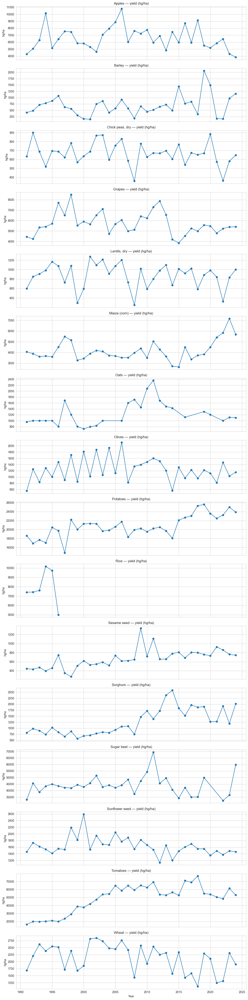

In [5]:
crops = fao_df['crop'].unique()
fig, axes = plt.subplots(len(crops), 1, figsize=(12, 3 * len(crops)), sharex=True)

for ax, crop in zip(axes, crops):
    sub = fao_df[fao_df['crop'] == crop].sort_values('year')
    ax.plot(sub['year'], sub['yield_hg_ha'], marker='o', linestyle='-')
    ax.set_title(f"{crop} — yield (hg/ha)")
    ax.set_ylabel("hg/ha")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

# Step 3 — Adapt the notebook's model to a single crop

In [6]:
from scipy.stats import multivariate_normal

def detect_anomalies_for_crop(fao_df, crop, z_thresh=2.0):
    sub = fao_df[fao_df['crop'] == crop].sort_values('year').reset_index(drop=True)
    X = sub[['year', 'yield_hg_ha']].values.astype(float)

    # --- Fit Gaussian (same math as notebook's estimate_parameters) ---
    mu = X.mean(axis=0)
    sigma = np.cov(X, rowvar=False)
    # small ridge to keep covariance invertible when years are near-linear
    sigma += np.eye(2) * 1e-6

    # --- PDF at every point (same math as notebook's multivariate_gaussian) ---
    p = multivariate_normal(mean=mu, cov=sigma).pdf(X)
    log_p = np.log(p + 1e-300)   # log-scale is more stable for plotting

    # --- Residual-based outlier flag (robust alternative to F1 without labels) ---
    # Years whose yield deviates strongly from the local trend
    resid = X[:, 1] - np.polyval(np.polyfit(X[:, 0], X[:, 1], 1), X[:, 0])
    resid_z = np.abs((resid - resid.mean()) / (resid.std() + 1e-12))
    outlier_mask = resid_z > z_thresh   # >zσ deviation from trend

    return sub, X, log_p, outlier_mask

## Step 4 — Plot anomalies

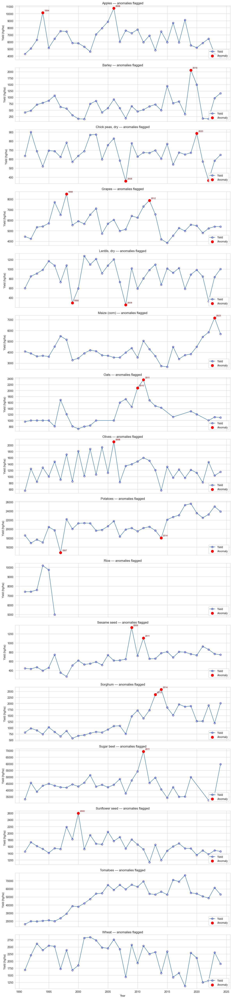

In [7]:
fig, axes = plt.subplots(len(crops), 1, figsize=(12, 3.2 * len(crops)), sharex=True)
if len(crops) == 1:
    axes = [axes]

for ax, crop in zip(axes, crops):
    sub, X, log_p, mask = detect_anomalies_for_crop(fao_df, crop)

    ax.plot(sub['year'], sub['yield_hg_ha'],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label='Yield')

    # highlight anomalies
    ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, 'yield_hg_ha'],
               color='red', s=90, zorder=5, label='Anomaly')

    # annotate the year next to each anomaly
    for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, 'yield_hg_ha']):
        ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                    xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{crop} — anomalies flagged")
    ax.set_ylabel("Yield (hg/ha)")
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

## Step 5 — Before deciding how to handle anomalies, inspect them

In [8]:
print("=== Flagged anomaly years per crop ===\n")
for crop in crops:
    sub, _, _, mask = detect_anomalies_for_crop(fao_df, crop)
    print(f"--- {crop} ---")
    print(sub.loc[mask, ['year', 'yield_hg_ha', 'flag']].to_string(index=False))
    print()

=== Flagged anomaly years per crop ===

--- Apples ---
 year  yield_hg_ha flag
 1994      10143.3    E
 2006      10781.4    A

--- Barley ---
 year  yield_hg_ha flag
 2019       2061.7    A

--- Chick peas, dry ---
 year  yield_hg_ha flag
 2008        357.5    A
 2020        884.9    A
 2022        362.2    A

--- Grapes ---
 year  yield_hg_ha flag
 1998       8489.8    A
 2012       7878.2    A

--- Lentils, dry ---
 year  yield_hg_ha flag
 1999        294.4    A
 2008        251.3    A

--- Maize (corn) ---
 year  yield_hg_ha flag
 2023       7166.0    A



--- Oats ---
 year  yield_hg_ha flag
 2010       2088.9    A
 2011       2359.9    A

--- Olives ---
 year  yield_hg_ha flag
 2006       2107.6    A

--- Potatoes ---
 year  yield_hg_ha flag
 1997      14797.3    A
 2014      18060.3    A

--- Rice ---
Empty DataFrame
Columns: [year, yield_hg_ha, flag]
Index: []

--- Sesame seed ---
 year  yield_hg_ha flag
 2009       1337.6    A
 2011       1108.0    A

--- Sorghum ---
 year  yield_hg_ha flag
 2013       2369.5    A
 2014       2580.2    A

--- Sugar beet ---
 year  yield_hg_ha flag
 2011      69392.8    A

--- Sunflower seed ---
 year  yield_hg_ha flag
 2000       2594.2    A

--- Tomatoes ---
Empty DataFrame
Columns: [year, yield_hg_ha, flag]
Index: []

--- Wheat ---
Empty DataFrame
Columns: [year, yield_hg_ha, flag]
Index: []



# NASA

## Step 1 — Load & Explore

In [9]:
nasa_df = pd.read_csv(NASA_FILE, parse_dates=['date'])
nasa_df['year'] = nasa_df['date'].dt.year
nasa_df = nasa_df.dropna()

print("Shape:", nasa_df.shape)
print("\nColumns:", nasa_df.columns.tolist())
print("\nDtypes:\n", nasa_df.dtypes)
print("\nGovernorates:", nasa_df['governorate'].nunique())
print(nasa_df['governorate'].unique())
print("\nDate range:", nasa_df['date'].min(), "→", nasa_df['date'].max())
print("\nYear range:", nasa_df['year'].min(), "→", nasa_df['year'].max())
print("\nMissing values:\n", nasa_df.isnull().sum())
print("\nHead:\n", nasa_df.head())

Shape: (166499, 12)

Columns: ['governorate', 'latitude', 'longitude', 'date', 't2m', 't2m_max', 't2m_min', 'prectotcorr', 'rh2m', 'solar_kwh_m2', 'ws2m', 'year']

Dtypes:
 governorate             object
latitude               float64
longitude              float64
date            datetime64[ns]
t2m                    float64
t2m_max                float64
t2m_min                float64
prectotcorr            float64
rh2m                   float64
solar_kwh_m2           float64
ws2m                   float64
year                     int32
dtype: object

Governorates: 13
['Al-Hasakah' 'Aleppo' 'Ar-Raqqah' 'As-Suwayda' 'Damascus' 'Daraa'
 'Deir ez-Zor' 'Hama' 'Homs' 'Idlib' 'Latakia' 'Quneitra' 'Tartus']

Date range: 1991-01-01 00:00:00 → 2026-11-03 00:00:00

Year range: 1991 → 2026

Missing values:
 governorate     0
latitude        0
longitude       0
date            0
t2m             0
t2m_max         0
t2m_min         0
prectotcorr     0
rh2m            0
solar_kwh_m2    0
ws2m      

## Step 2 — Aggregate daily → yearly, per governorate

In [10]:
nasa_yearly_df = (
    nasa_df.groupby(['governorate', 'year'])
           .agg(
               t2m_mean        = ('t2m',           'mean'),
               t2m_max_extreme = ('t2m_max',       'max'),
               t2m_min_extreme = ('t2m_min',       'min'),
               precip_total    = ('prectotcorr',   'sum'),
               rh2m_mean       = ('rh2m',          'mean'),
               solar_mean      = ('solar_kwh_m2',  'mean'),
               ws2m_mean       = ('ws2m',          'mean'),
               n_days          = ('date',          'count'),
           )
           .reset_index()
)

nasa_yearly_df = nasa_yearly_df[nasa_yearly_df['n_days'] >= 300].reset_index(drop=True)

print("Aggregated shape:", nasa_yearly_df.shape)
print(nasa_yearly_df.groupby('governorate')['year'].agg(['min', 'max', 'count']))

Aggregated shape: (456, 10)
              min   max  count
governorate                   
Al-Hasakah   1991  2025     35
Aleppo       1991  2026     36
Ar-Raqqah    1991  2025     35
As-Suwayda   1991  2025     35
Damascus     1991  2025     35
Daraa        1991  2025     35
Deir ez-Zor  1991  2025     35
Hama         1991  2025     35
Homs         1991  2025     35
Idlib        1991  2025     35
Latakia      1991  2025     35
Quneitra     1991  2025     35
Tartus       1991  2025     35


## Step 3 — Visualize: all governorates, one panel each

In [11]:
CLIMATE_FEATURES = ['t2m_mean', 't2m_max_extreme', 't2m_min_extreme',
                    'precip_total', 'rh2m_mean', 'solar_mean', 'ws2m_mean']

def detect_anomalies_for_gov(nasa_yearly_df, gov, feature, z_thresh=2.0):
    sub = (nasa_yearly_df[nasa_yearly_df['governorate'] == gov]
           .sort_values('year').reset_index(drop=True))

    # Drop rows where the feature is NaN or inf
    finite = np.isfinite(sub[feature].values.astype(float))
    dropped = (~finite).sum()
    if dropped:
        warnings.warn(f"{gov}: dropped {dropped} non-finite {feature} rows "
                      f"(years {sub.loc[~finite, 'year'].tolist()})")

    sub = sub.loc[finite].reset_index(drop=True)
    if len(sub) < 3:
        warnings.warn(f"{gov}: only {len(sub)} usable rows — cannot fit Gaussian. "
                      f"Returning empty mask.")
        return sub, None, None, np.zeros(len(sub), dtype=bool)

    X = sub[['year', feature]].values.astype(float)

    mu = X.mean(axis=0)
    sigma = np.cov(X, rowvar=False) + np.eye(2) * 1e-6

    p = multivariate_normal(mean=mu, cov=sigma).pdf(X)
    log_p = np.log(p + 1e-300)

    resid = X[:, 1] - np.polyval(np.polyfit(X[:, 0], X[:, 1], 1), X[:, 0])
    resid_z = np.abs((resid - resid.mean()) / (resid.std() + 1e-12))
    outlier_mask = resid_z > z_thresh

    return sub, X, log_p, outlier_mask

## Step 4 — Anomaly detection per governorate

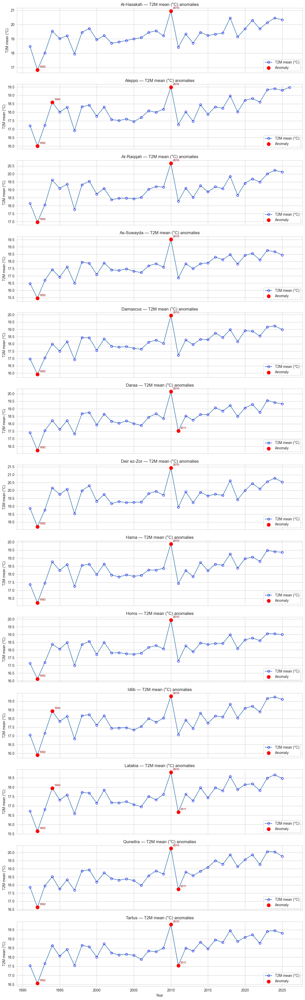

In [18]:
FEATURE = 't2m_mean'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

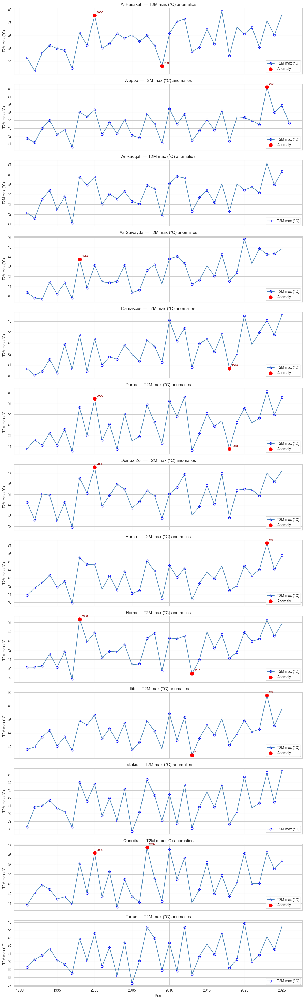

In [19]:
FEATURE = 't2m_max_extreme'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

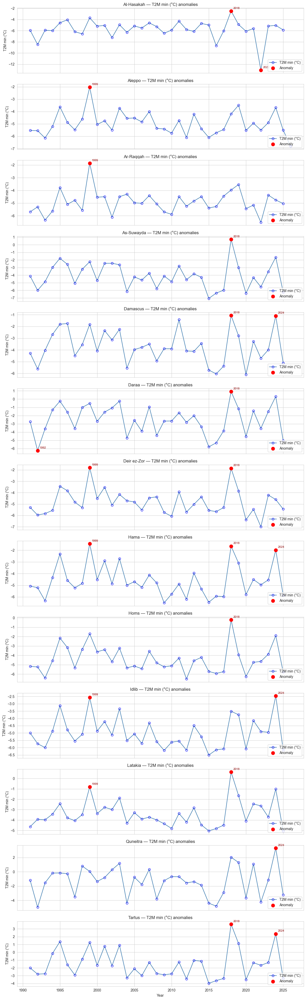

In [20]:
FEATURE = 't2m_min_extreme'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

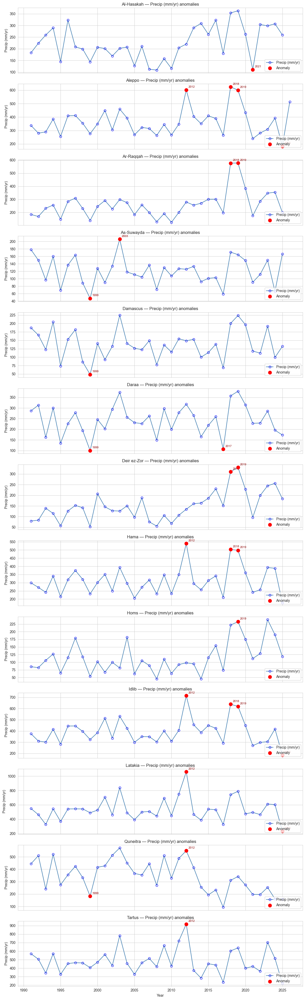

In [21]:
FEATURE = 'precip_total'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

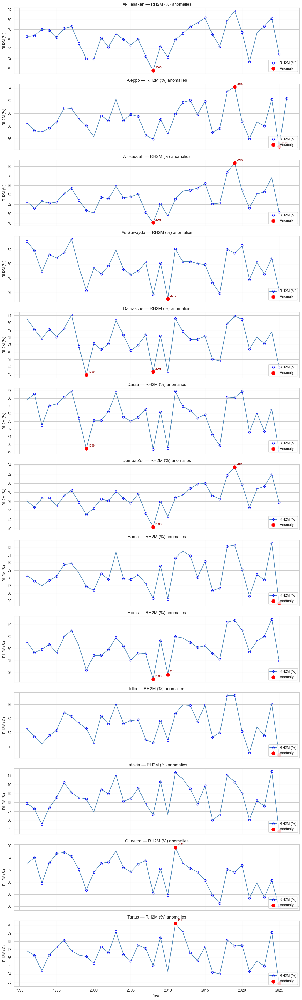

In [22]:
FEATURE = 'rh2m_mean'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

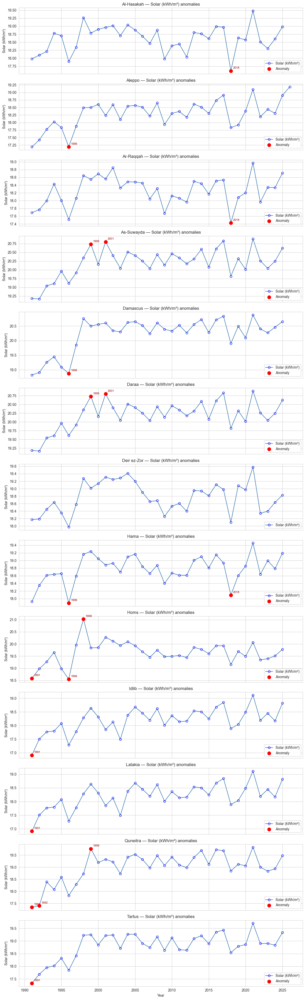

In [23]:
FEATURE = 'solar_mean'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

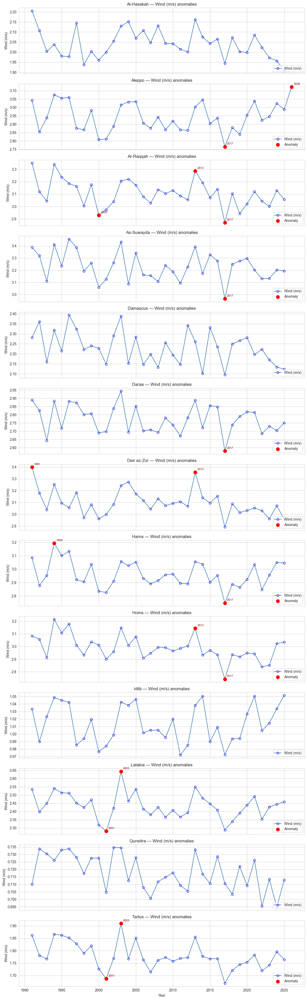

In [24]:
FEATURE = 'ws2m_mean'
LABELS = {
    't2m_mean'        : 'T2M mean (°C)',
    't2m_max_extreme' : 'T2M max (°C)',
    't2m_min_extreme' : 'T2M min (°C)',
    'precip_total'    : 'Precip (mm/yr)',
    'rh2m_mean'       : 'RH2M (%)',
    'solar_mean'      : 'Solar (kWh/m²)',
    'ws2m_mean'       : 'Wind (m/s)',
}

govs = sorted(nasa_yearly_df['governorate'].unique())
fig, axes = plt.subplots(len(govs), 1, figsize=(12, 3.0 * len(govs)), sharex=True)
if len(govs) == 1:
    axes = [axes]

for ax, gov in zip(axes, govs):
    sub, X, log_p, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)

    if X is None:
        ax.text(0.5, 0.5, f"{gov}: insufficient data",
                transform=ax.transAxes, ha='center', va='center', fontsize=10)
        ax.set_title(f"{gov} — skipped")
        ax.grid(True)
        continue

    ax.plot(sub['year'], sub[FEATURE],
            marker='o', linestyle='-', color='steelblue',
            markerfacecolor='none', markeredgecolor='blue', label=LABELS[FEATURE])

    if mask.any():
        ax.scatter(sub.loc[mask, 'year'], sub.loc[mask, FEATURE],
                   color='red', s=90, zorder=5, label='Anomaly')
        for y, v in zip(sub.loc[mask, 'year'], sub.loc[mask, FEATURE]):
            ax.annotate(str(int(y)), (y, v), textcoords="offset points",
                        xytext=(6, 6), fontsize=8, color='darkred')

    ax.set_title(f"{gov} — {LABELS[FEATURE]} anomalies")
    ax.set_ylabel(LABELS[FEATURE])
    ax.legend(loc="lower right")
    ax.grid(True)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

In [13]:
print("NaN counts per column after aggregation:")
print(nasa_yearly_df[CLIMATE_FEATURES].isnull().sum())

print("\nRows with any NaN in features:")
bad = nasa_yearly_df[nasa_yearly_df[CLIMATE_FEATURES].isnull().any(axis=1)]
print(bad[['governorate', 'year', 'n_days'] + CLIMATE_FEATURES].to_string(index=False))

NaN counts per column after aggregation:
t2m_mean           0
t2m_max_extreme    0
t2m_min_extreme    0
precip_total       0
rh2m_mean          0
solar_mean         0
ws2m_mean          0
dtype: int64

Rows with any NaN in features:
Empty DataFrame
Columns: [governorate, year, n_days, t2m_mean, t2m_max_extreme, t2m_min_extreme, precip_total, rh2m_mean, solar_mean, ws2m_mean]
Index: []


## Step 5 — Before deciding how to handle anomalies, inspect them

In [14]:
print(f"=== Flagged {LABELS[FEATURE]} anomaly years per governorate ===\n")
for gov in govs:
    sub, _, _, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, FEATURE)
    print(f"--- {gov} ---")
    cols = ['year', FEATURE, 'n_days']
    print(sub.loc[mask, cols].to_string(index=False))
    print()

=== Flagged Precip (mm/yr) anomaly years per governorate ===

--- Al-Hasakah ---
 year  precip_total  n_days
 2021        111.09     365

--- Aleppo ---
 year  precip_total  n_days
 2012        601.78     366
 2018        624.49     365
 2019        599.93     365
 2025        183.33     365

--- Ar-Raqqah ---
 year  precip_total  n_days
 2018        576.82     365
 2019        578.02     365

--- As-Suwayda ---
 year  precip_total  n_days
 1999         47.33     365
 2003        206.20     365

--- Damascus ---
 year  precip_total  n_days
 1999         48.49     365

--- Daraa ---
 year  precip_total  n_days
 1999         99.78     365
 2017        106.50     365

--- Deir ez-Zor ---
 year  precip_total  n_days
 2018        310.79     365
 2019        330.89     365

--- Hama ---
 year  precip_total  n_days
 2012        539.63     366
 2018        503.29     365
 2019        497.94     365

--- Homs ---
 year  precip_total  n_days
 2019        232.64     365

--- Idlib ---
 year  prec

## All features in one graph per governorate

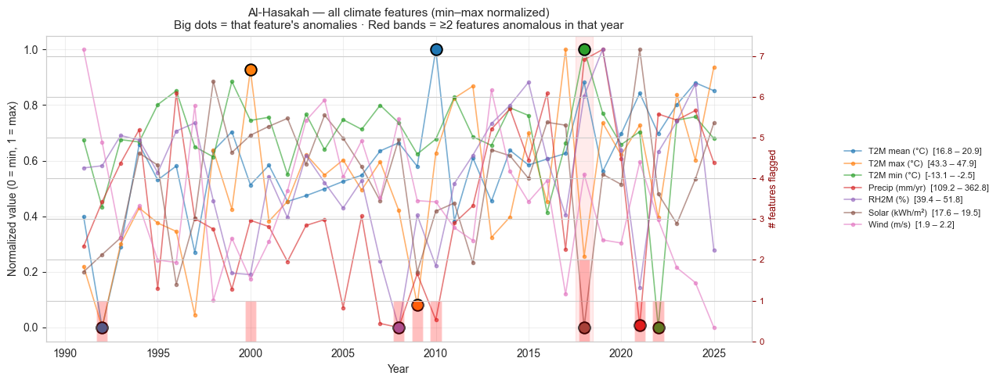

Al-Hasakah     strong anomaly years: [2018]


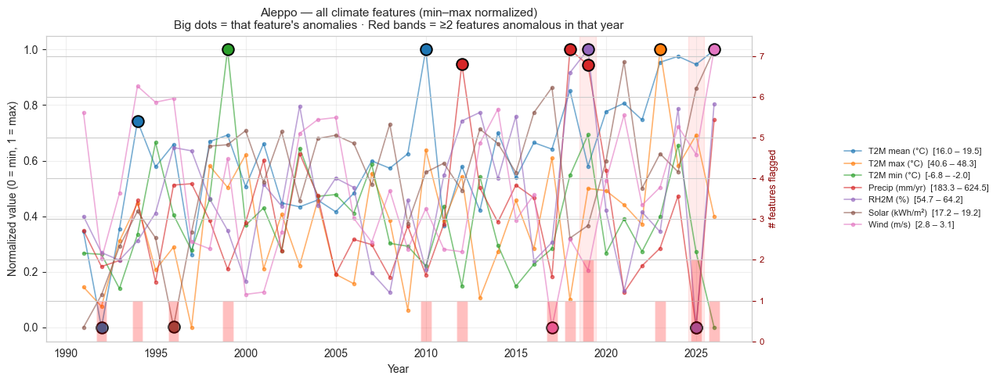

Aleppo         strong anomaly years: [2019, 2025]


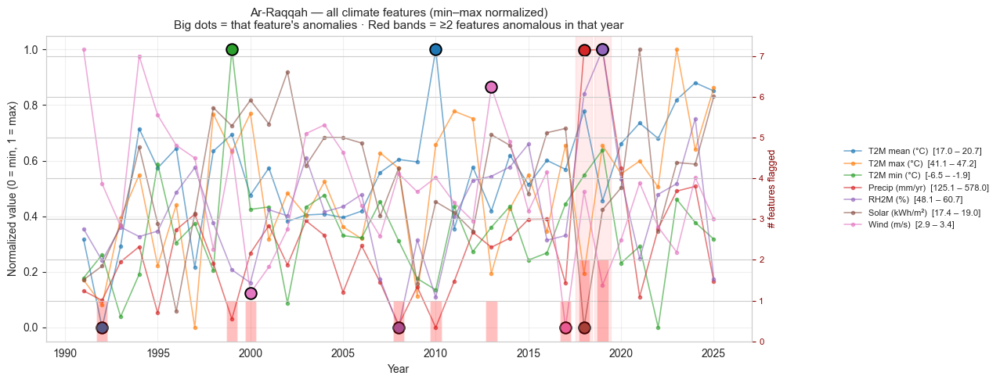

Ar-Raqqah      strong anomaly years: [2018, 2019]


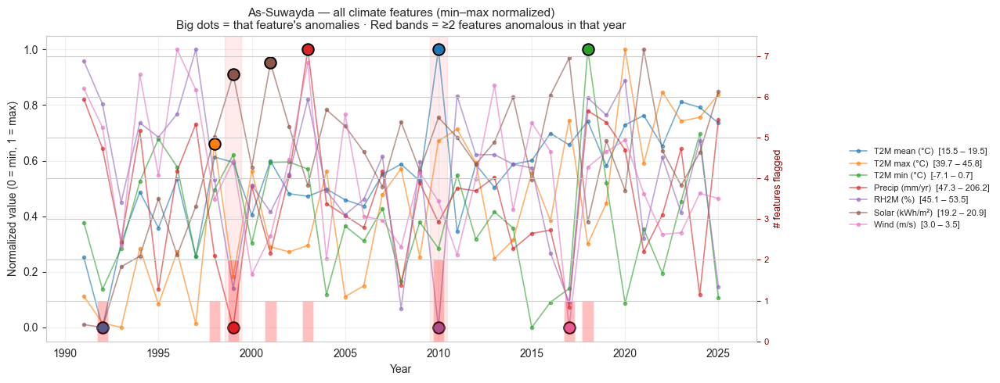

As-Suwayda     strong anomaly years: [1999, 2010]


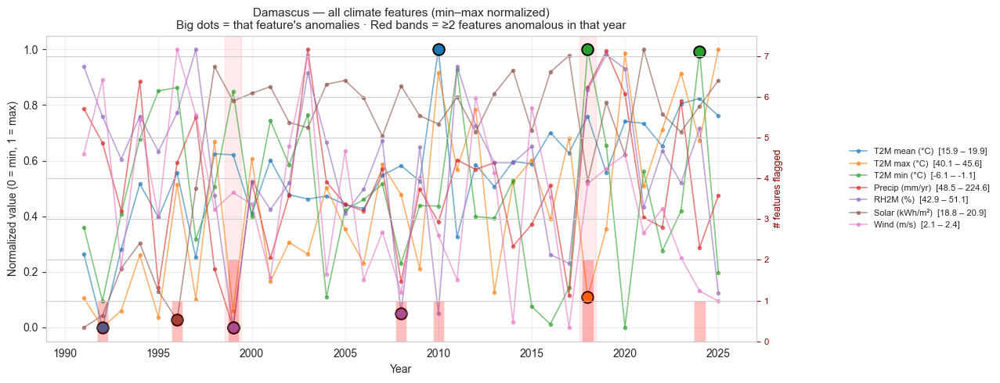

Damascus       strong anomaly years: [1999, 2018]


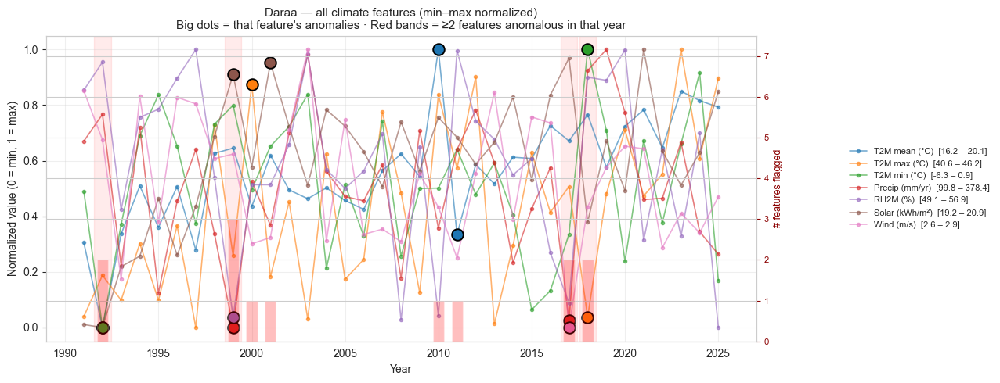

Daraa          strong anomaly years: [1992, 1999, 2017, 2018]


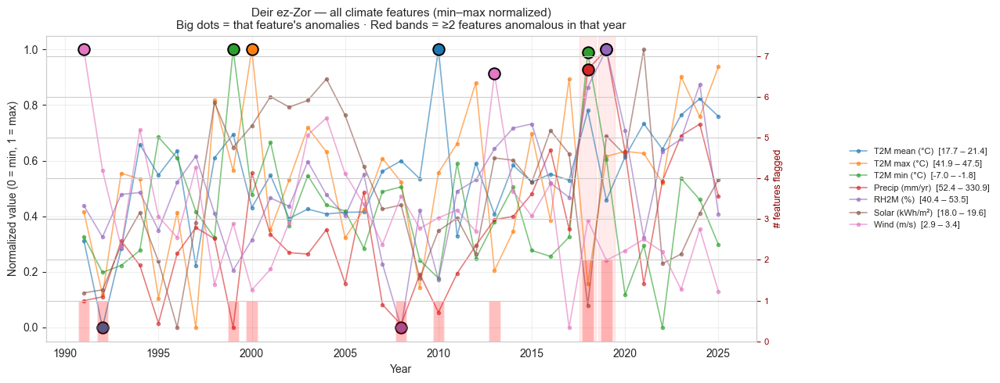

Deir ez-Zor    strong anomaly years: [2018, 2019]


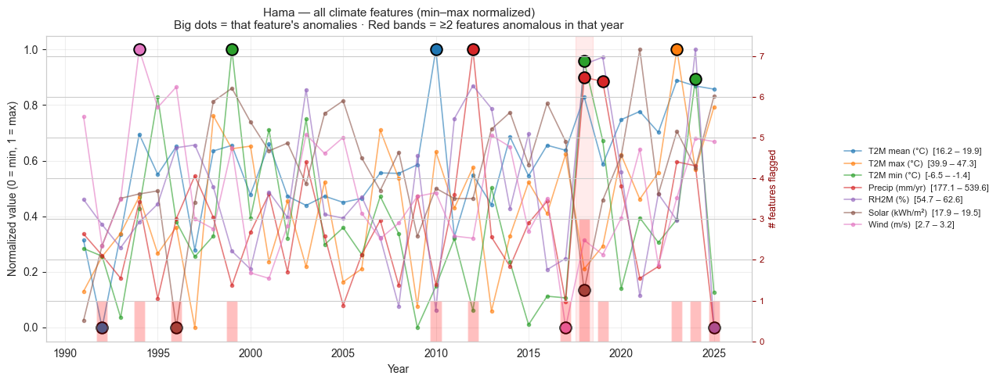

Hama           strong anomaly years: [2018]


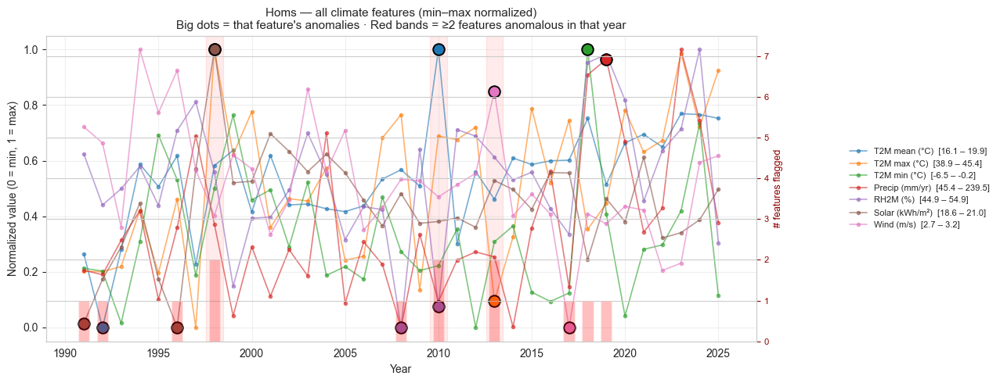

Homs           strong anomaly years: [1998, 2010, 2013]


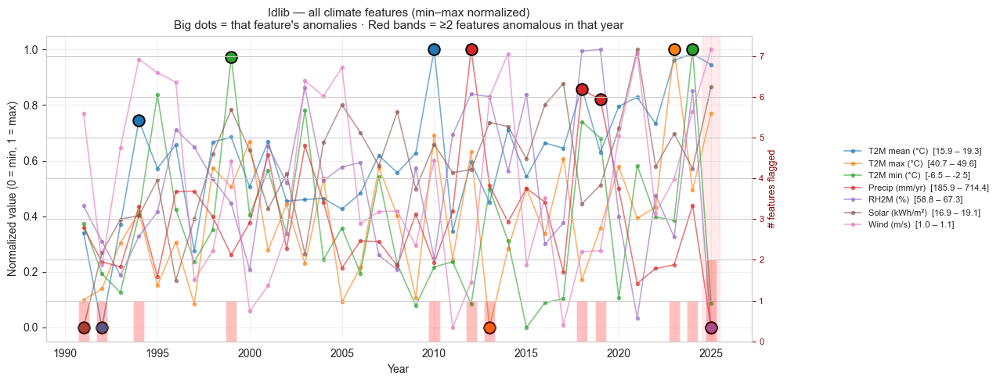

Idlib          strong anomaly years: [2025]


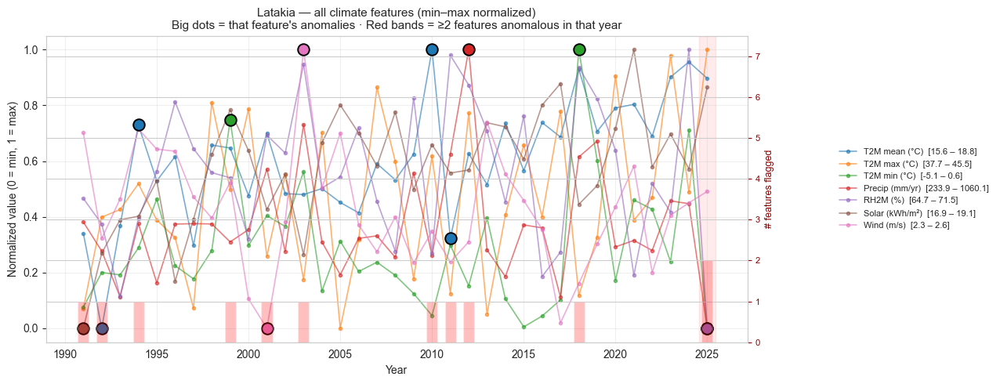

Latakia        strong anomaly years: [2025]


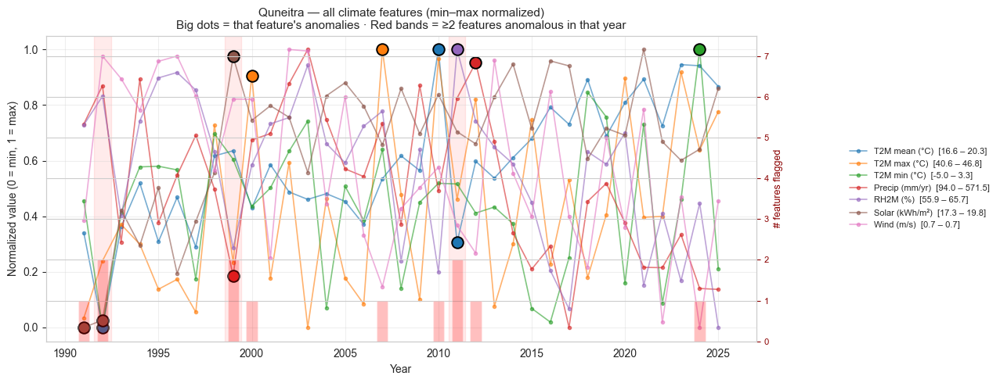

Quneitra       strong anomaly years: [1992, 1999, 2011]


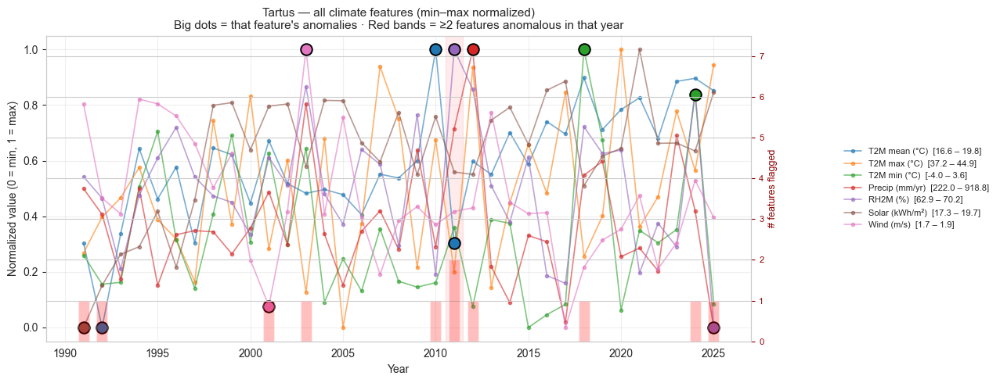

Tartus         strong anomaly years: [2011]


In [25]:
for gov in govs:
    sub = nasa_yearly_df[nasa_yearly_df['governorate'] == gov].sort_values('year').reset_index(drop=True)
    years = sub['year'].values

    # ── 1. Run anomaly detection for every feature, per year ──────
    feat_masks = {}
    for feat in CLIMATE_FEATURES:
        _, _, _, m = detect_anomalies_for_gov(nasa_yearly_df, gov, feat)
        feat_masks[feat] = m

    # Per-year count of flagged features (0 = clean, 7 = every feature odd)
    anomaly_count = np.sum([m for m in feat_masks.values()], axis=0)

    # ── 2. Plot ────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(13, 5))

    # Base lines (thin, semi-transparent so red dots pop)
    for feat in CLIMATE_FEATURES:
        vals = sub[feat].values.astype(float)
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        rng = vmax - vmin if (vmax - vmin) > 0 else 1.0
        norm = (vals - vmin) / rng

        line, = ax.plot(
            years, norm,
            marker='o', linewidth=1.2, markersize=3, alpha=0.6,
            label=f"{LABELS[feat]}  [{vmin:.1f} – {vmax:.1f}]",
        )
        color = line.get_color()

        # Anomaly markers on THIS feature's curve, in its own color,
        # but emphasized (bigger, filled, black outline) so they stand out.
        mask = feat_masks[feat]
        if mask.any():
            ax.scatter(
                years[mask], norm[mask],
                s=110, color=color,
                edgecolors='black', linewidths=1.4,
                zorder=10, alpha=1.0,
            )

    # ── 3. Shade years where ≥2 features are anomalous ────────────
    strong_years = years[anomaly_count >= 2]
    for y in strong_years:
        ax.axvspan(y - 0.45, y + 0.45, color='red', alpha=0.08, zorder=0)

    # ── 4. Bottom strip: count of flagged features per year ───────
    ax2 = ax.twinx()
    ax2.bar(years, anomaly_count, width=0.6,
            color='red', alpha=0.25, zorder=1)
    ax2.set_ylabel("# features flagged", color='darkred', fontsize=9)
    ax2.tick_params(axis='y', colors='darkred', labelsize=8)
    ax2.set_ylim(0, len(CLIMATE_FEATURES) + 0.5)

    # ── 5. Cosmetics ──────────────────────────────────────────────
    ax.set_title(
        f"{gov} — all climate features (min–max normalized)\n"
        f"Big dots = that feature's anomalies · "
        f"Red bands = ≥2 features anomalous in that year",
        fontsize=11,
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Normalized value (0 = min, 1 = max)")
    ax.legend(loc='center left', bbox_to_anchor=(1.12, 0.5),
              fontsize=8, frameon=False)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ── 6. Console summary (useful when scanning 13 governorates) ──
    if len(strong_years):
        print(f"{gov:<14} strong anomaly years: {list(map(int, strong_years))}")
    else:
        print(f"{gov:<14} no strong anomaly years")

# # Combined view — FAO yield anomalies + NASA climate anomalies

In [26]:
# ── FAO: for each year, count how many crops were flagged as anomalous ──
fao_years = sorted(fao_df['year'].unique())
fao_anomaly_by_year = {y: 0 for y in fao_years}

for crop in crops:
    sub, _, _, mask = detect_anomalies_for_crop(fao_df, crop)
    for y, m in zip(sub['year'], mask):
        if m:
            fao_anomaly_by_year[y] += 1

# ── NASA: for each (governorate, year), count climate features flagged ──
# Then collapse across governorates by taking the max (worst governorate)
nasa_years = sorted(nasa_yearly_df['year'].unique())
nasa_anomaly_by_year = {y: 0 for y in nasa_years}

for gov in govs:
    for feat in CLIMATE_FEATURES:
        sub, _, _, mask = detect_anomalies_for_gov(nasa_yearly_df, gov, feat)
        for y, m in zip(sub['year'], mask):
            if m:
                nasa_anomaly_by_year[y] += 1
# Normalize so it's comparable to FAO (which maxes at #crops):
# rescaled to a 0–N_crops scale by dividing by max then multiplying by N_crops
nasa_max = max(nasa_anomaly_by_year.values()) or 1
n_crops = len(crops)
nasa_anomaly_scaled = {y: v / nasa_max * n_crops for y, v in nasa_anomaly_by_year.items()}

print("FAO anomaly counts per year (nonzero):")
print({y: v for y, v in fao_anomaly_by_year.items() if v})
print("\nNASA anomaly counts per year (nonzero, top 15 by severity):")
top = sorted(nasa_anomaly_by_year.items(), key=lambda x: -x[1])[:15]
print(dict(top))

FAO anomaly counts per year (nonzero):
{np.int64(1994): 1, np.int64(1997): 1, np.int64(1998): 1, np.int64(1999): 1, np.int64(2000): 1, np.int64(2006): 2, np.int64(2008): 2, np.int64(2009): 1, np.int64(2010): 1, np.int64(2011): 3, np.int64(2012): 1, np.int64(2013): 1, np.int64(2014): 2, np.int64(2019): 1, np.int64(2020): 1, np.int64(2022): 1, np.int64(2023): 1}

NASA anomaly counts per year (nonzero, top 15 by severity):
{np.int32(2018): 19, np.int32(1992): 15, np.int32(1999): 15, np.int32(2010): 15, np.int32(2019): 9, np.int32(2025): 8, np.int32(2017): 7, np.int32(1991): 6, np.int32(2011): 6, np.int32(2012): 6, np.int32(2000): 5, np.int32(2008): 5, np.int32(2013): 5, np.int32(2024): 5, np.int32(1994): 4}


C:\Users\MK1349\AppData\Local\Temp\ipykernel_6664\3236034622.py:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


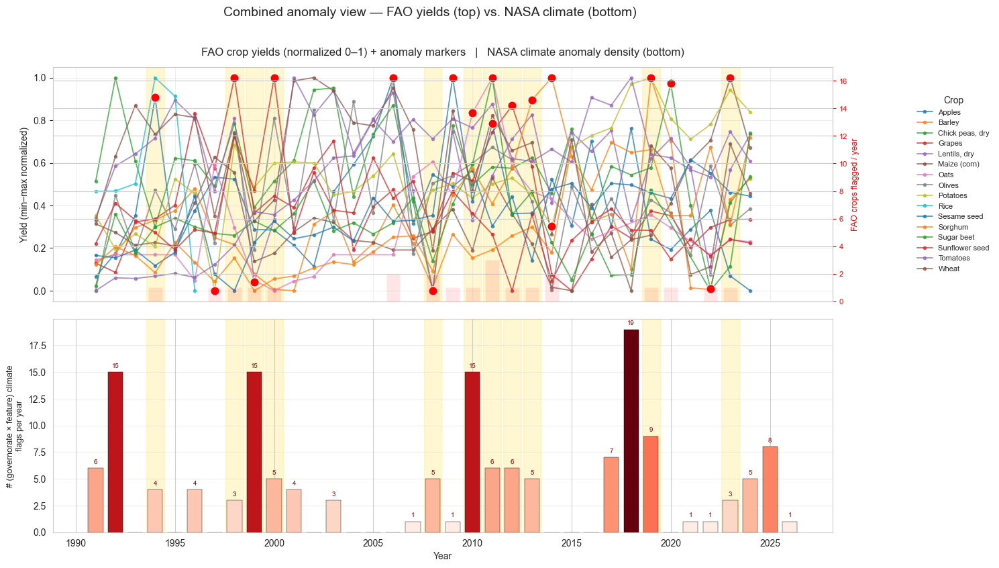


Years flagged in BOTH datasets (gold bands): [np.int64(1994), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2008), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2019), np.int64(2023)]


In [28]:
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True,
    gridspec_kw={'height_ratios': [1.1, 1], 'hspace': 0.08}
)

# ═══════════════════════ TOP — FAO yields ═══════════════════════
for crop in crops:
    sub, _, _, mask = detect_anomalies_for_crop(fao_df, crop)

    # Make sure we're working with a plain numpy boolean array
    mask = np.asarray(mask, dtype=bool)

    vals = sub['yield_hg_ha'].values.astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    rng = vmax - vmin if (vmax - vmin) > 0 else 1.0
    norm = (vals - vmin) / rng

    ax_top.plot(sub['year'], norm, marker='o', linewidth=1.3, markersize=3,
                alpha=0.75, label=crop)

    # ── FIXED: index the numpy array directly with the boolean mask ──
    if mask.any():
        ax_top.scatter(
            sub['year'].values[mask],
            norm[mask],
            color='red', s=90, zorder=5,
            edgecolors='white', linewidths=0.8,
        )

# FAO anomaly-count strip on the top axis
ax_top_far = ax_top.twinx()
years_fao = sorted(fao_anomaly_by_year.keys())
ax_top_far.bar(years_fao,
               [fao_anomaly_by_year[y] for y in years_fao],
               color='red', alpha=0.10, width=0.7)
ax_top_far.set_ylabel("FAO crops flagged / year", color='red', fontsize=9)
ax_top_far.tick_params(axis='y', colors='red', labelsize=8)
ax_top_far.set_ylim(0, len(crops) + 1)

ax_top.set_title(
    "FAO crop yields (normalized 0–1) + anomaly markers   |   "
    "NASA climate anomaly density (bottom)",
    fontsize=12, pad=12)
ax_top.set_ylabel("Yield (min–max normalized)")
ax_top.legend(loc='center left', bbox_to_anchor=(1.10, 0.5),
              fontsize=8, frameon=False, title="Crop")
ax_top.grid(True, alpha=0.3)

# ═══════════════════════ BOTTOM — NASA climate anomalies ═══════════════════════
years_nasa  = sorted(nasa_anomaly_by_year.keys())
values_nasa = [nasa_anomaly_by_year[y] for y in years_nasa]

bar_colors = plt.cm.Reds(np.array(values_nasa) / (max(values_nasa) + 1e-9))
ax_bot.bar(years_nasa, values_nasa, color=bar_colors,
           edgecolor='black', linewidth=0.3, width=0.75)

for y, v in zip(years_nasa, values_nasa):
    if v > 0:
        ax_bot.text(y, v + 0.3, str(int(v)),
                    ha='center', va='bottom', fontsize=7, color='darkred')

ax_bot.set_ylabel("# (governorate × feature) climate\nflags per year", fontsize=9)
ax_bot.set_xlabel("Year")
ax_bot.grid(True, alpha=0.3, axis='y')

# ═══════════════════════ SHARED HIGHLIGHT ═══════════════════════
common_anom_years = [
    y for y in years_fao
    if fao_anomaly_by_year.get(y, 0) > 0
    and nasa_anomaly_by_year.get(y, 0) >= 3
]
for y in common_anom_years:
    ax_top.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)
    ax_bot.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)

plt.suptitle("Combined anomaly view — FAO yields (top) vs. NASA climate (bottom)",
             fontsize=14, y=0.98)

plt.tight_layout()
plt.show()

print(f"\nYears flagged in BOTH datasets (gold bands): {common_anom_years}")

C:\Users\MK1349\AppData\Local\Temp\ipykernel_6664\2824083325.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


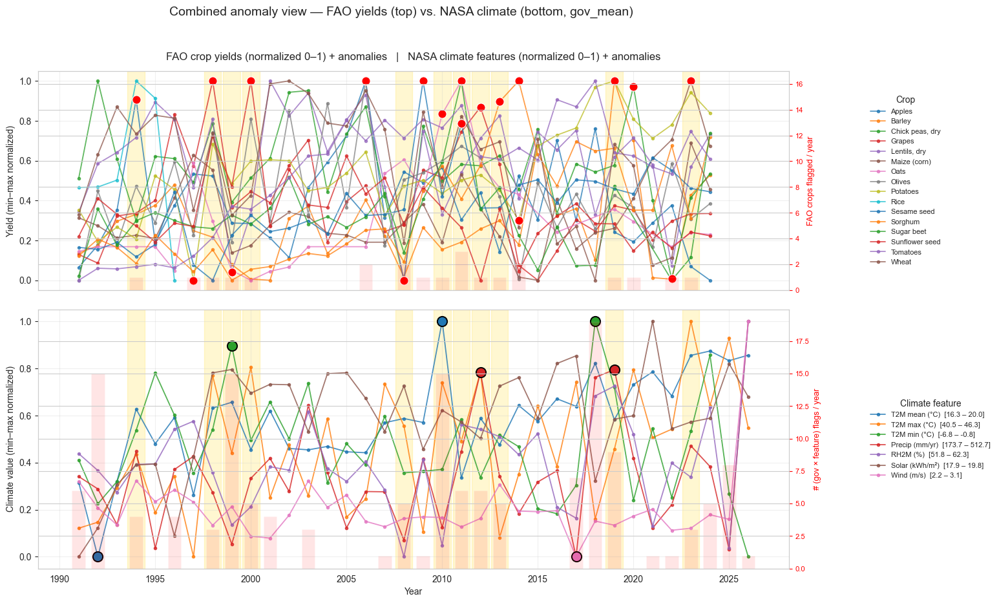


Years flagged in BOTH datasets (gold bands): [np.int64(1994), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2008), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2019), np.int64(2023)]


In [29]:
BOTTOM_MODE = 'gov_mean'   # 'gov_mean' or 'per_gov'

# ── Pre-compute per-(gov, feature) anomaly masks once ─────────────
# (reused by both modes; cheaper than recomputing)
feature_masks = {}          # {(gov, feat): mask array}
for gov in govs:
    sub_gov = nasa_yearly_df[nasa_yearly_df['governorate'] == gov].sort_values('year').reset_index(drop=True)
    for feat in CLIMATE_FEATURES:
        _, _, _, m = detect_anomalies_for_gov(nasa_yearly_df, gov, feat)
        feature_masks[(gov, feat)] = np.asarray(m, dtype=bool)

# Reusable palette so the same feature has the same color across governors
feat_colors = {f: plt.cm.tab10(i) for i, f in enumerate(CLIMATE_FEATURES)}

# ═══════════════════════ FIGURE ═══════════════════════
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(15, 10), sharex=True,
    gridspec_kw={'height_ratios': [1.1, 1.3], 'hspace': 0.08}
)

# ═══════════════════════ TOP — FAO yields ═══════════════════════
for crop in crops:
    sub, _, _, mask = detect_anomalies_for_crop(fao_df, crop)
    mask = np.asarray(mask, dtype=bool)

    vals = sub['yield_hg_ha'].values.astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    rng = vmax - vmin if (vmax - vmin) > 0 else 1.0
    norm = (vals - vmin) / rng

    ax_top.plot(sub['year'], norm, marker='o', linewidth=1.3, markersize=3,
                alpha=0.75, label=crop)
    if mask.any():
        ax_top.scatter(sub['year'].values[mask], norm[mask],
                       color='red', s=90, zorder=5,
                       edgecolors='white', linewidths=0.8)

ax_top_far = ax_top.twinx()
years_fao = sorted(fao_anomaly_by_year.keys())
ax_top_far.bar(years_fao,
               [fao_anomaly_by_year[y] for y in years_fao],
               color='red', alpha=0.10, width=0.7)
ax_top_far.set_ylabel("FAO crops flagged / year", color='red', fontsize=9)
ax_top_far.tick_params(axis='y', colors='red', labelsize=8)
ax_top_far.set_ylim(0, len(crops) + 1)

ax_top.set_title(
    "FAO crop yields (normalized 0–1) + anomalies   |   "
    "NASA climate features (normalized 0–1) + anomalies",
    fontsize=12, pad=12)
ax_top.set_ylabel("Yield (min–max normalized)")
ax_top.legend(loc='center left', bbox_to_anchor=(1.10, 0.5),
              fontsize=8, frameon=False, title="Crop")
ax_top.grid(True, alpha=0.3)

# ═══════════════════════ BOTTOM — NASA climate features ═══════════════════════
if BOTTOM_MODE == 'gov_mean':
    # Average each feature across governorates, then normalize to 0–1.
    # Anomaly markers: a year is flagged for the feature if ≥ 50 % of
    # governorates flagged that same year for that feature.
    for feat in CLIMATE_FEATURES:
        # Mean value across governors per year
        mean_series = (
            nasa_yearly_df.groupby('year')[feat]
                          .mean()
                          .sort_index()
        )
        years_f = mean_series.index.values
        vals    = mean_series.values.astype(float)
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        rng_v = vmax - vmin if (vmax - vmin) > 0 else 1.0
        norm    = (vals - vmin) / rng_v

        color = feat_colors[feat]
        ax_bot.plot(years_f, norm,
                    marker='o', linewidth=1.3, markersize=3,
                    alpha=0.8, color=color,
                    label=f"{LABELS[feat]}  [{vmin:.1f} – {vmax:.1f}]")

        # Per-year "vote": how many governors flagged this feature that year
        n_gov = nasa_yearly_df['governorate'].nunique()
        votes = np.zeros(len(years_f), dtype=int)
        for gov in govs:
            m = feature_masks[(gov, feat)]
            gov_years = (nasa_yearly_df[nasa_yearly_df['governorate'] == gov]
                         .sort_values('year')['year'].values)
            # Align to mean_series' year axis
            for y, flag in zip(gov_years, m):
                if flag:
                    idx = np.where(years_f == y)[0]
                    if len(idx):
                        votes[idx[0]] += 1

        # Feature is anomalous in a year if majority of governors flagged it
        consensus = votes >= max(1, n_gov // 2)
        if consensus.any():
            ax_bot.scatter(years_f[consensus], norm[consensus],
                           color=color, s=120, zorder=10,
                           edgecolors='black', linewidths=1.4)

    # Bottom strip: total flags across all (gov × feature) per year
    ax_bot_far = ax_bot.twinx()
    years_nasa  = sorted(nasa_anomaly_by_year.keys())
    values_nasa = [nasa_anomaly_by_year[y] for y in years_nasa]
    ax_bot_far.bar(years_nasa, values_nasa, width=0.7,
                   color='red', alpha=0.10, zorder=0)
    ax_bot_far.set_ylabel("# (gov × feature) flags / year",
                         color='red', fontsize=9)
    ax_bot_far.tick_params(axis='y', colors='red', labelsize=8)

else:  # 'per_gov' — one line per (governorate, feature)
    for gov in govs:
        sub_gov = (nasa_yearly_df[nasa_yearly_df['governorate'] == gov]
                   .sort_values('year').reset_index(drop=True))
        years_g = sub_gov['year'].values
        for feat in CLIMATE_FEATURES:
            vals = sub_gov[feat].values.astype(float)
            vmin, vmax = np.nanmin(vals), np.nanmax(vals)
            rng_v = vmax - vmin if (vmax - vmin) > 0 else 1.0
            norm  = (vals - vmin) / rng_v

            color = feat_colors[feat]
            ax_bot.plot(years_g, norm,
                        linewidth=0.8, alpha=0.35, color=color)

            mask = feature_masks[(gov, feat)]
            if mask.any():
                ax_bot.scatter(years_g[mask], norm[mask],
                               color=color, s=45, alpha=0.85,
                               edgecolors='black', linewidths=0.6,
                               zorder=8)

    # Legend is feature-based, not gov-based
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], color=feat_colors[f], lw=2,
                      label=LABELS[f]) for f in CLIMATE_FEATURES]
    ax_bot.legend(handles=handles,
                  loc='center left', bbox_to_anchor=(1.10, 0.5),
                  fontsize=8, frameon=False, title="Climate feature")

# Common bottom-panel cosmetics
ax_bot.set_ylabel("Climate value (min–max normalized)")
ax_bot.set_xlabel("Year")
ax_bot.grid(True, alpha=0.3)
if BOTTOM_MODE == 'gov_mean':
    ax_bot.legend(loc='center left', bbox_to_anchor=(1.10, 0.5),
                  fontsize=8, frameon=False, title="Climate feature")

# ═══════════════════════ SHARED HIGHLIGHT ═══════════════════════
common_anom_years = [
    y for y in years_fao
    if fao_anomaly_by_year.get(y, 0) > 0
    and nasa_anomaly_by_year.get(y, 0) >= 3
]
for y in common_anom_years:
    ax_top.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)
    ax_bot.axvspan(y - 0.45, y + 0.45, color='gold', alpha=0.18, zorder=0)

plt.suptitle(
    f"Combined anomaly view — FAO yields (top) vs. NASA climate (bottom, {BOTTOM_MODE})",
    fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

print(f"\nYears flagged in BOTH datasets (gold bands): {common_anom_years}")